# 01 · Exploratory data analysis — agrivoltaic farm sensor export

**Data:** Grafana export of 2026-09-24 (`data/raw/grafana_export_2026-09-24/`), processed by
`python scripts/make_dataset.py` into `data/processed/`. All timestamps are **UTC**.

**Plots:** `R1` = open-field reference, `S1`/`S2` = crop beds under the single-axis PV trackers,
`WS` = WS100 weather station, `TRK` = trackers M01–M10, `SITE` = site-level daily weather summary.

**Resolution caveat:** apart from precipitation (30 s), the export holds **12-hour means**
(buckets 00–12 and 12–24 UTC) or daily values. Daily totals and means are exact, but the
diurnal cycle — midday peaks, night-time minima — is not visible in this export.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

from agrivoltaics.config import FIGURES_DIR, PROCESSED_DIR
from agrivoltaics.data.cleaning import SUSPECT_SENSORS
from agrivoltaics.data.load import load_resolution, trim_empty
from agrivoltaics.features.microclimate import IRRADIANCE_MEAN_TO_KWH, PPFD_MEAN_TO_DLI, plot_mean
from agrivoltaics.viz import style
from agrivoltaics.viz.style import INK, INK_MUTED, INK_SECONDARY, PLOT_COLORS, PLOT_LABELS, SURFACE

style.apply()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 2)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

d12 = pd.read_parquet(PROCESSED_DIR / "sensors_12h.parquet")
daily = pd.read_parquet(PROCESSED_DIR / "daily.parquet")
meta = pd.read_csv(PROCESSED_DIR / "sensors_meta.csv", index_col="name", parse_dates=["first_valid", "last_valid"])
qc = pd.read_csv(PROCESSED_DIR / "qc_log.csv")
for df in (d12, daily):            # matplotlib is simplest with naive timestamps; everything is UTC
    df.index = df.index.tz_convert(None)

PLOTS3 = ["R1", "S1", "S2"]

def by_plot(df, quantity, plots=PLOTS3):
    """Plot-level mean of one quantity (suspect sensors excluded)."""
    return pd.concat({p: plot_mean(df, meta, p, quantity) for p in plots}, axis=1)

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

def label_end(ax, series, text, color, dy=0):
    """Direct label at the last valid point of a line."""
    s = series.dropna()
    ax.annotate(text, (s.index[-1], s.iloc[-1]), xytext=(6, dy), textcoords="offset points",
                color=INK_SECONDARY, fontsize=8.5, va="center")

def zero_line(ax):
    ax.axhline(0, color=style.AXIS, lw=0.9, zorder=1)

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

print(f"12 h table: {d12.shape},  daily table: {daily.shape}")
print(f"12 h period: {d12.index.min():%Y-%m-%d} -> {d12.index.max():%Y-%m-%d}")

12 h table: (980, 74),  daily table: (515, 90)
12 h period: 2025-05-22 -> 2026-09-24


## 1. What is in the export

Twenty CSV files, 18 loaded (two are exact duplicates of other panels). The table lists each
panel, its resolution, and when its sensors first and last reported.

In [2]:
inventory = (
    meta.groupby(["resolution", "panel"])
    .agg(series=("quantity", "size"),
         sensor=("sensor", lambda s: ", ".join(sorted(set(s)))),
         unit=("unit", lambda s: ", ".join(sorted(set(s.dropna()) - {""})) or "text"),
         first=("first_valid", "min"), last=("last_valid", "max"))
    .sort_values(["resolution", "first"])
)
inventory["first"] = inventory["first"].dt.date
inventory["last"] = inventory["last"].dt.date
inventory

series              sensor       unit       first        last
resolution panel                                                                             
12h        tracker_angle            10  tracker controller        deg  2025-05-22  2026-09-02
           air_temperature          11         WS100, Z8AI       degC  2025-06-16  2026-09-24
           dew_point                 6                Z8AI       degC  2025-06-18  2026-09-24
           irradiance                4         pyranometer       W/m2  2025-06-18  2026-09-24
           par                       6               SQ618  umol/m2/s  2025-06-18  2026-09-24
           pv_temperature            8    PV module sensor       degC  2025-06-18  2026-09-24
           soil_temperature         14              HD3910       degC  2025-06-18  2026-09-24
           soil_vwc                 14              HD3910          %  2025-06-18  2026-09-07
           wind_speed                1                Z8AI        m/s  2025-06-18  2026-09-24
1D         site_wind_direction       1             unknown        deg  2025-04-28  2026-09-02
           site_wind_speed           1             unknown        m/s  2025-04-28  2026-09-02
           site_temperature          1             unknown       degC  2025-05-22  2026-09-02
           relative_humidity         6                Z8AI          %  2025-06-18  2026-09-24
30s        precip_cumulative         1               WS100         mm  2025-06-16  2026-09-24
           precip_type               1               WS100       text  2025-06-16  2026-09-24
           precip_wmo_wawa           1               WS100       text  2025-06-16  2026-09-24
           precip_wmo_ww             1               WS100       text  2025-06-16  2026-09-24
           precip_intensity          1               WS100       mm/h  2025-07-14  2026-09-24

### Coverage over time

Share of 12 h buckets (or days) with data, per series and week. The export window starts on
2024-09-24 but no sensor reported before **late April 2025**; most came online on
**2025-06-18**, two of the four reference soil probes only in **October 2025**, and the tracker
feed and site weather summary stop on **2026-09-02**.

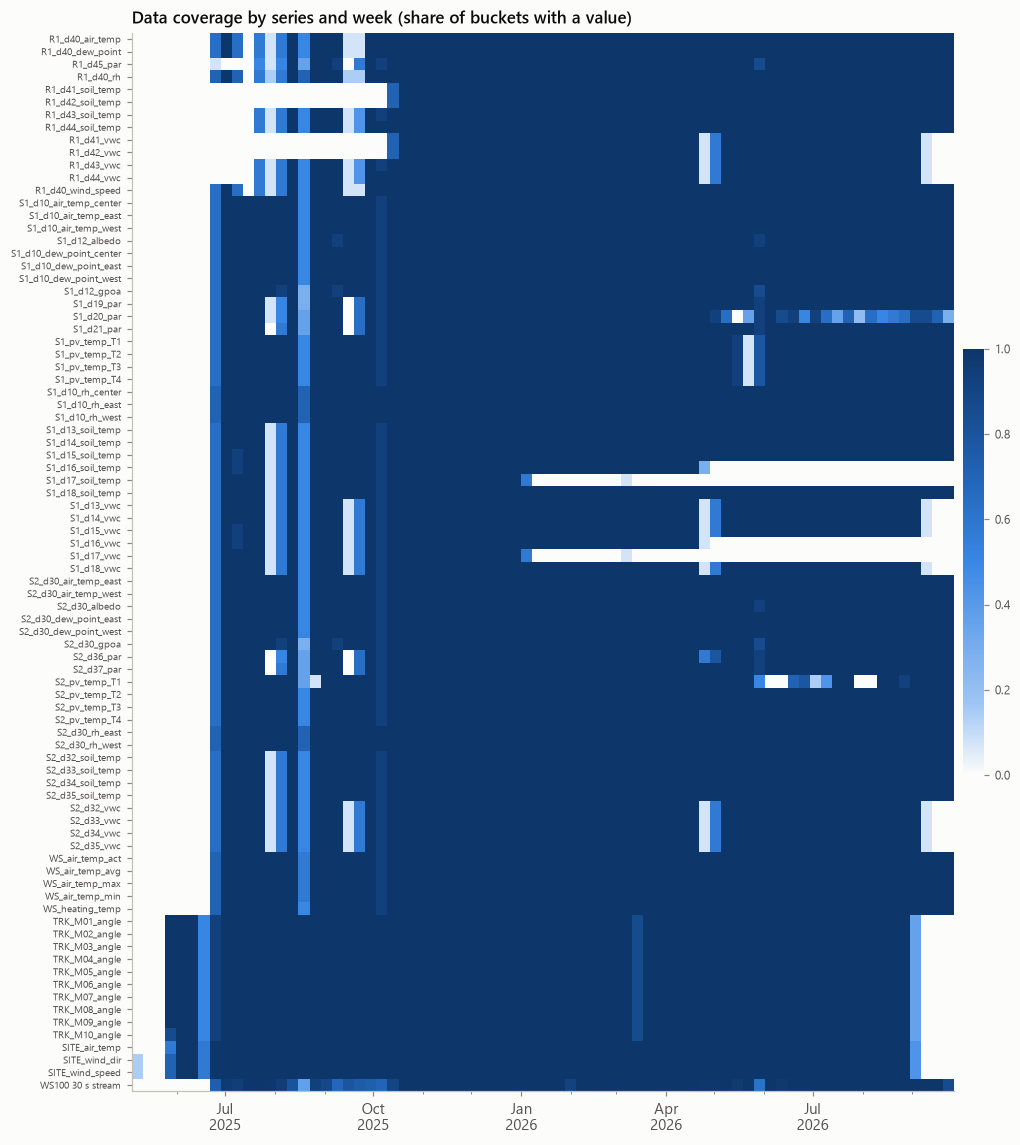

In [3]:
cols12 = [c for c in d12.columns]
cols1 = meta.index[meta.resolution == "1D"].tolist()
cov = pd.concat([d12[cols12].notna().resample("W").mean(),
                 daily[cols1].notna().resample("W").mean(),
                 daily[["WS_coverage"]].resample("W").mean().rename(columns={"WS_coverage": "WS100 30 s stream"})], sort=True,
                axis=1)
order = (meta.loc[cols12 + cols1].assign(o=lambda m: m["plot"].map({"R1": 0, "S1": 1, "S2": 2, "WS": 3, "TRK": 4, "SITE": 5}))
         .sort_values(["o", "quantity"]).index.tolist()) + ["WS100 30 s stream"]
cov = cov[order].T

cmap = LinearSegmentedColormap.from_list("cov", [SURFACE] + style.SEQUENTIAL_BLUE[1:])
fig, ax = plt.subplots(figsize=(10, 12.5))
im = ax.imshow(cov.values, aspect="auto", cmap=cmap, vmin=0, vmax=1, interpolation="nearest",
               extent=[mdates.date2num(cov.columns[0]), mdates.date2num(cov.columns[-1]), len(cov) - 0.5, -0.5])
ax.set_yticks(range(len(cov)), cov.index, fontsize=6.5)
ax.grid(False)
month_axis(ax)
ax.set_title("Data coverage by series and week (share of buckets with a value)")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
save(fig, "01_coverage")

## 2. Data quality

`scripts/make_dataset.py` applies the rules in `src/agrivoltaics/data/cleaning.py` and logs every
value it changes. The parser also handles three export traps:

* **Unit auto-scaling:** Grafana writes cumulative precipitation in `µm` below 1 mm and in `mm`
  above (53 k of 1.24 M rows). A naive parse turns 0.92 mm into 920 mm.
* **Duplicates:** two series repeated within a panel, and 10 duplicated rows in each 30 s file.
* **Local time with DST:** timestamps are CET/CEST; buckets are 00:00/12:00 UTC.

In [4]:
summary = qc.groupby(["rule", "action"])["n"].agg(values="sum", columns="size").sort_values("values", ascending=False)
display(summary)
print("Suspect sensors (kept, excluded from plot-level means):")
for k, v in SUSPECT_SENSORS.items():
    print(f"  {k}: {v}")

,,values,columns
rule,action,,
~0 over a 12 h bucket (logger outage),removed,239,8
deviates > 10 K from sibling module sensors,removed,106,1
PAR inconsistent with POA irradiance (PAR logger outage),removed,81,6
VWC dropout (< 1 %),removed,25,4
12 h mean above 1200 (partial bucket),removed,24,6
small negative offset,clipped to 0,12,3
12 h mean above 600 (partial bucket),removed,10,2
12 h mean above 100 (partial bucket),removed,3,2
exact-zero dropout,removed,1,1


Suspect sensors (kept, excluded from plot-level means):
  S1_d20_par: erratic relative to S1_d19/S1_d21 (monthly ratio 0.3-1.9), fails the PAR/POA consistency check ~2.5x more often than its neighbours; its 16-bit channel is broken


Three faults that would distort any downstream model if left in:

* **`S2_pv_temp_T1` drifts** to 60–105 °C for weeks (Jun–Aug 2026) while the other three S2
  module sensors read 30–45 °C. Removed where it departs more than 10 K from its siblings.
* **PAR logger outages** (21–30 Jul and 8–13 Sep 2025): all six ePAR sensors report 0 while the
  pyranometers keep measuring. A 12 h mean of zero is impossible because every bucket contains
  daylight, so both full and partial outages are removed.
* **Partial buckets:** a few 12 h means exceed what clear sky allows (POA > 600 W/m²,
  PAR > 1200 µmol/m²/s). They share timestamps across sensors, which points to logger gaps that
  left only midday samples in the bucket.

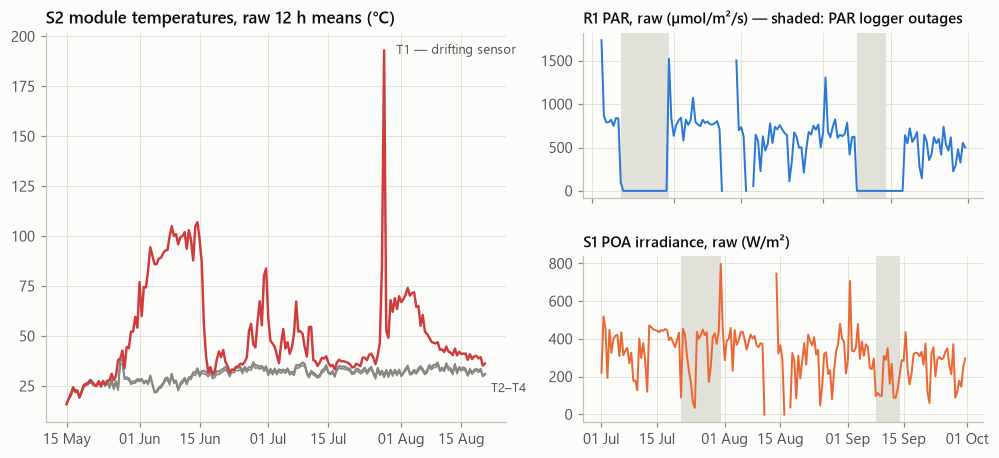

In [5]:
raw12, _ = load_resolution("12h")
raw12.index = raw12.index.tz_convert(None)

fig = plt.figure(figsize=(11, 4.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1], hspace=0.35, wspace=0.18)
ax = fig.add_subplot(gs[:, 0])
w = raw12.loc["2026-05-15":"2026-08-20"]
for c in ["S2_pv_temp_T2", "S2_pv_temp_T3", "S2_pv_temp_T4"]:
    ax.plot(w.index, w[c], color=INK_MUTED, lw=1.1)
ax.plot(w.index, w["S2_pv_temp_T1"], color="#d03b3b", lw=1.6)
ax.annotate("T1 — drifting sensor", (w["S2_pv_temp_T1"].idxmax(), w["S2_pv_temp_T1"].max()), xytext=(8, 0),
            textcoords="offset points", fontsize=8.5, color=INK_SECONDARY, va="center")
ax.annotate("T2–T4", (w.index[-1], w["S2_pv_temp_T3"].iloc[-1]), xytext=(4, -12), textcoords="offset points",
            fontsize=8.5, color=INK_SECONDARY)
ax.set_title("S2 module temperatures, raw 12 h means (°C)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

w = raw12.loc["2025-07-01":"2025-09-30"]
outages = [("2025-07-21", "2025-07-31"), ("2025-09-08", "2025-09-14")]
for i, (col, title) in enumerate([("R1_d45_par", "R1 PAR, raw (µmol/m²/s) — shaded: PAR logger outages"), ("S1_d12_gpoa", "S1 POA irradiance, raw (W/m²)")]):
    a = fig.add_subplot(gs[i, 1])
    for lo, hi in outages:
        a.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color=style.GRID, lw=0)
    a.plot(w.index, w[col], color=PLOT_COLORS["R1"] if col.startswith("R1") else PLOT_COLORS["S1"], lw=1.3)
    a.set_title(title, fontsize=10)
    a.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    if i == 0:
        a.tick_params(labelbottom=False)
save(fig, "02_quality_examples")

## 3. Weather context

Daily means are computed from the two 12 h buckets (days missing one are dropped).
Precipitation comes from the 30 s WS100 stream: summed increments of the cumulative counter,
cross-checked against integrated intensity.

Total precipitation 578 mm (counter) vs 548 mm (intensity) — daily correlation r = 0.992
Hours by precipitation type: {'WS_minutes_liquid_precipitation': 402.0, 'WS_minutes_no_precipitation': 10132.0, 'WS_minutes_solid_precipitation': 3.0, 'WS_minutes_sleet': 1.0}


date,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
precip_mm,NaN,NaN,0.0,35.0,72.0,34.0,31.0,19.0,112.0,84.0,25.0,46.0,16.0,28.0,12.0,2.0,6.0,55.0
rain_h,0.0,0.0,2.0,18.0,9.0,15.0,29.0,10.0,80.0,98.0,31.0,42.0,22.0,15.0,8.0,2.0,10.0,10.0


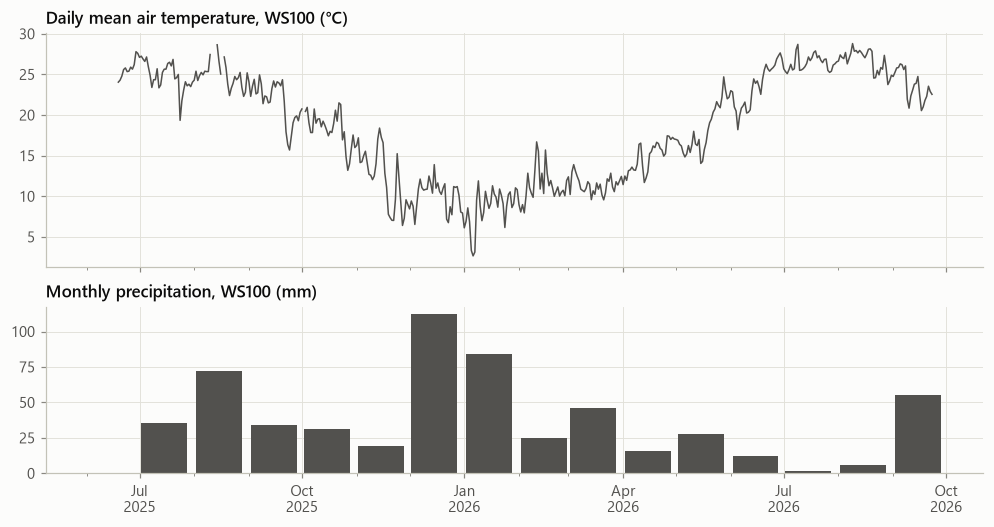

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
t = daily["WS_air_temp_avg"]
a1.plot(t.index, t, color=INK_SECONDARY, lw=1.0)
a1.set_title("Daily mean air temperature, WS100 (°C)")
monthly_p = daily["WS_precip_mm"].resample("MS").sum(min_count=1)
a2.bar(monthly_p.index + pd.Timedelta(days=14), monthly_p, width=26, color=INK_SECONDARY)
a2.set_title("Monthly precipitation, WS100 (mm)")
month_axis(a2)
save(fig, "03_weather")

p = daily[["WS_precip_mm", "WS_precip_mm_from_intensity"]].dropna()
print(f"Total precipitation {daily.WS_precip_mm.sum():.0f} mm (counter) vs {daily.WS_precip_mm_from_intensity.sum():.0f} mm (intensity)"
      f" — daily correlation r = {p.corr().iloc[0, 1]:.3f}")
mins = daily.filter(like="WS_minutes_").sum() / 60
print("Hours by precipitation type:", mins.round(0).to_dict())
pd.DataFrame({"precip_mm": monthly_p, "rain_h": daily["WS_minutes_liquid_precipitation"].resample("MS").sum() / 60}).T.round(0)

**Do the overlapping weather sources agree?**

In [7]:
temps = daily[["WS_air_temp_avg", "SITE_air_temp", "R1_d40_air_temp"]].dropna()
wind = daily[["R1_d40_wind_speed", "SITE_wind_speed"]].dropna()
print("Air temperature (common days):", temps.mean().round(2).to_dict(), " min pairwise r =", temps.corr().min().min().round(3))
print("Wind speed m/s (common days):", wind.mean().round(2).to_dict(), " r =", wind.corr().iloc[0, 1].round(2))
sectors = pd.cut(daily["SITE_wind_dir"] % 360, np.arange(-22.5, 360, 45), labels=["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
print("Predominant daily wind direction:", sectors.value_counts().to_dict())

Air temperature (common days): {'WS_air_temp_avg': 17.79, 'SITE_air_temp': 18.51, 'R1_d40_air_temp': 18.54}  min pairwise r = 0.997
Wind speed m/s (common days): {'R1_d40_wind_speed': 1.67, 'SITE_wind_speed': 2.29}  r = 0.91
Predominant daily wind direction: {'S': 180, 'SE': 136, 'SW': 85, 'W': 47, 'NW': 11, 'E': 5, 'N': 2, 'NE': 2}


## 4. Light under the panels

Daily light integral (DLI) = daily mean ePAR × 0.0864 (mol/m²/day). The SQ618 measures
*extended* PAR (380–760 nm), so values run higher than classic 400–700 nm PAR.

Paired days: 402.  Overall transmission: S1 64.3%, S2 63.3%
Per sensor (% of R1): {'S1_d19_par': '60%', 'S1_d20_par': '78%', 'S1_d21_par': '69%', 'S2_d36_par': '61%', 'S2_d37_par': '65%'}
POA insolation by month (kWh/m²/day): {Timestamp('2025-06-01 00:00:00'): 10.3, Timestamp('2025-07-01 00:00:00'): 8.4, Timestamp('2025-08-01 00:00:00'): 7.9, Timestamp('2025-09-01 00:00:00'): 6.2, Timestamp('2025-10-01 00:00:00'): 4.6, Timestamp('2025-11-01 00:00:00'): 3.3, Timestamp('2025-12-01 00:00:00'): 2.0, Timestamp('2026-01-01 00:00:00'): 2.4, Timestamp('2026-02-01 00:00:00'): 4.0, Timestamp('2026-03-01 00:00:00'): 5.6, Timestamp('2026-04-01 00:00:00'): 8.5, Timestamp('2026-05-01 00:00:00'): 8.3, Timestamp('2026-06-01 00:00:00'): 10.0, Timestamp('2026-07-01 00:00:00'): 9.4, Timestamp('2026-08-01 00:00:00'): 8.0, Timestamp('2026-09-01 00:00:00'): 7.2}


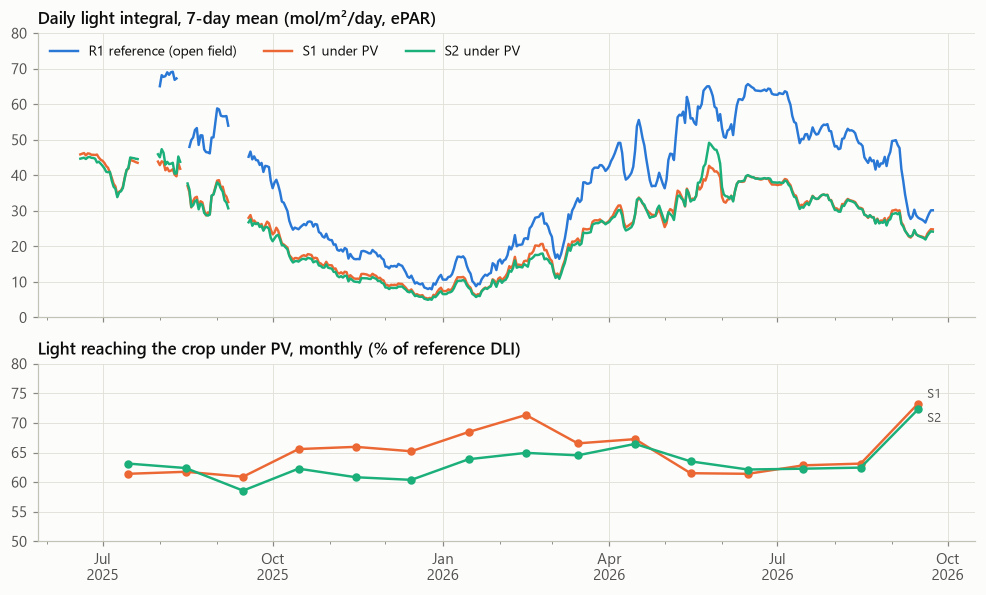

In [8]:
dli = by_plot(daily, "par") * PPFD_MEAN_TO_DLI
paired = dli.dropna()
monthly = paired.resample("MS").sum()
transmission = monthly[["S1", "S2"]].div(monthly["R1"], axis=0)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for p in PLOTS3:
    s = dli[p].rolling(7, min_periods=4, center=True).mean()
    a1.plot(s.index, s, color=PLOT_COLORS[p], label=PLOT_LABELS[p])
a1.set_title("Daily light integral, 7-day mean (mol/m²/day, ePAR)")
a1.legend(loc="upper left", ncols=3); a1.set_ylim(0, 80)
for p in ["S1", "S2"]:
    x = transmission.index + pd.Timedelta(days=14)
    a2.plot(x, transmission[p] * 100, color=PLOT_COLORS[p], marker="o", ms=4.5, label=PLOT_LABELS[p])
    label_end(a2, pd.Series((transmission[p] * 100).values, index=x), p, PLOT_COLORS[p], dy=6 if p == "S1" else -6)
a2.set_ylim(50, 80)
a2.set_title("Light reaching the crop under PV, monthly (% of reference DLI)")
month_axis(a2)
save(fig, "04_light")

print(f"Paired days: {len(paired)}.  Overall transmission: S1 {paired.S1.sum()/paired.R1.sum():.1%}, S2 {paired.S2.sum()/paired.R1.sum():.1%}")
per_sensor = {c: daily[[c, "R1_d45_par"]].dropna().pipe(lambda x: x[c].sum() / x["R1_d45_par"].sum())
              for c in meta.index[(meta.quantity == "par") & (meta["plot"] != "R1")]}
print("Per sensor (% of R1):", {k: f"{v:.0%}" for k, v in per_sensor.items()})
poa = daily[["S1_d12_gpoa", "S2_d30_gpoa"]].mean(axis=1) * IRRADIANCE_MEAN_TO_KWH
print("POA insolation by month (kWh/m²/day):", poa.resample("MS").mean().round(1).dropna().to_dict())

## 5. Soil moisture

Volumetric water content (VWC, %) per plot, averaged over the HD3910 probes: 4 in R1, 6 in S1,
4 in S2. Until 2025-10-08 only two of the four R1 probes were running (dashed line).

date,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
R1,NaN,NaN,NaN,16.2,10.1,17.5,23.0,21.9,24.8,25.9,24.7,24.8,25.3,22.4,21.2,25.8,27.8,27.9
S1,NaN,NaN,29.2,29.1,15.8,22.7,27.2,26.7,30.7,30.9,29.2,29.5,29.3,23.7,17.5,22.5,24.8,26.4
S2,NaN,NaN,29.3,26.7,14.3,18.4,21.0,20.2,24.3,25.8,25.2,25.2,25.5,22.3,19.4,23.6,26.7,28.0


Per-probe mean VWC since 2025-10-08:
R1_d41_vwc    23.4
R1_d42_vwc    24.9
R1_d43_vwc    25.1
R1_d44_vwc    24.1
S1_d13_vwc    25.2
S1_d14_vwc    27.3
S1_d15_vwc    29.9
S1_d16_vwc    30.5
S1_d17_vwc    26.9
S1_d18_vwc    22.7
S2_d32_vwc    19.4
S2_d33_vwc    27.1
S2_d34_vwc    26.1
S2_d35_vwc    21.9


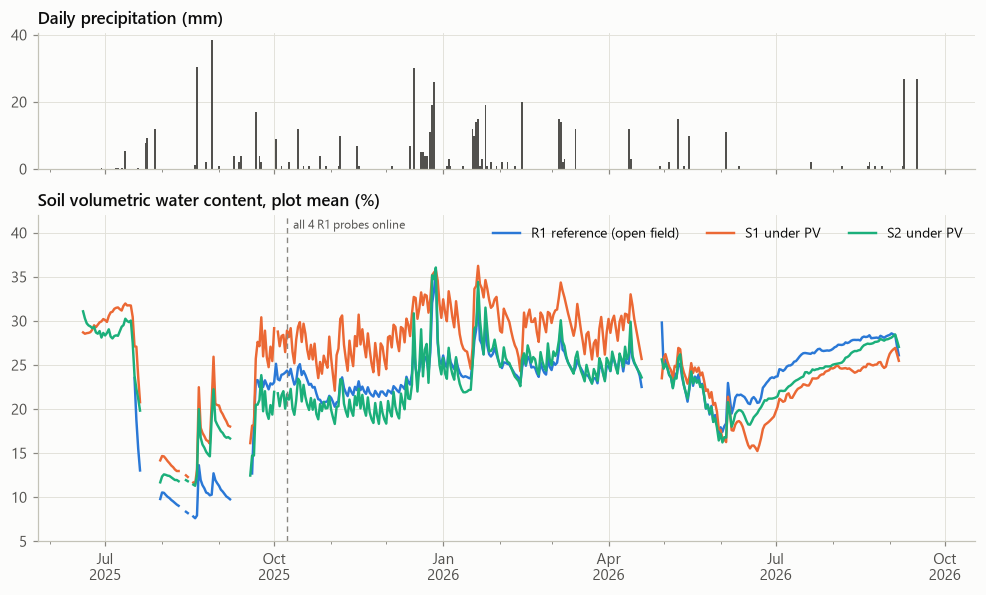

In [9]:
vwc = by_plot(daily, "vwc")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2.4]})
a1.bar(daily.index, daily["WS_precip_mm"], width=1.0, color=INK_SECONDARY)
a1.set_title("Daily precipitation (mm)")
for p in PLOTS3:
    a2.plot(vwc.index, vwc[p], color=PLOT_COLORS[p], label=PLOT_LABELS[p])
a2.set_ylim(5, 42)
a2.axvline(pd.Timestamp("2025-10-08"), color=INK_MUTED, lw=0.9, ls=(0, (4, 3)))
a2.annotate("all 4 R1 probes online", (pd.Timestamp("2025-10-08"), 41.5), xytext=(4, 0),
            textcoords="offset points", fontsize=8, color=INK_SECONDARY, va="top")
a2.set_title("Soil volumetric water content, plot mean (%)")
a2.legend(loc="upper right", ncols=3)
month_axis(a2)
save(fig, "05_soil_moisture")

display(vwc.resample("MS").mean().T.round(1))
print("Per-probe mean VWC since 2025-10-08:")
print(daily.loc["2025-10-08":, meta.index[meta.quantity == "vwc"]].mean().round(1).to_string())

## 6. Soil temperature

date,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
R1,NaN,NaN,NaN,29.0,28.9,25.8,20.5,13.8,11.3,9.3,11.2,13.2,17.3,22.6,26.5,29.2,29.1,26.3
S1,NaN,NaN,28.2,27.3,27.2,24.4,19.5,13.5,11.2,9.1,10.9,12.5,16.4,21.1,25.3,27.8,28.4,26.1
S2,NaN,NaN,28.0,27.2,27.2,24.4,19.7,14.1,11.6,9.4,11.1,12.7,16.3,20.9,25.5,28.2,28.2,25.1


R1 probes on common days (mean °C): {'R1_d41_soil_temp': 19.15, 'R1_d42_soil_temp': 19.26, 'R1_d43_soil_temp': 18.78, 'R1_d44_soil_temp': 19.0}


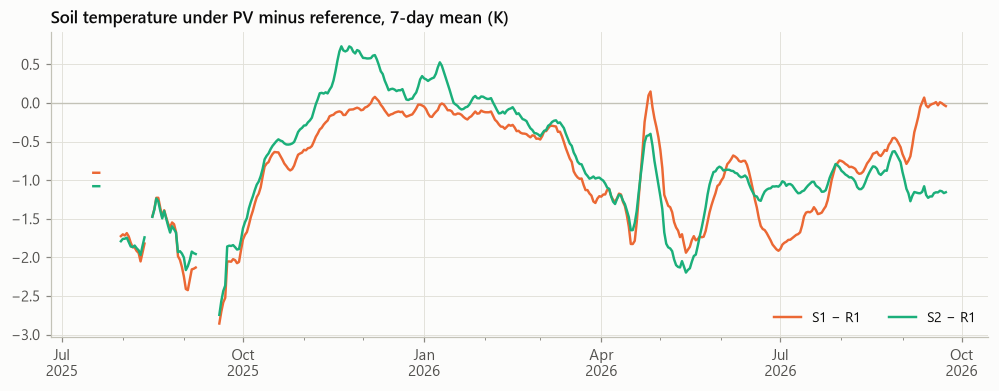

In [10]:
st = by_plot(daily, "soil_temp")
diff = st[["S1", "S2"]].sub(st["R1"], axis=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
zero_line(ax)
for p in ["S1", "S2"]:
    s = diff[p].rolling(7, min_periods=4, center=True).mean()
    ax.plot(s.index, s, color=PLOT_COLORS[p], label=f"{p} − R1")
ax.set_title("Soil temperature under PV minus reference, 7-day mean (K)")
ax.legend(loc="lower right", ncols=2)
month_axis(ax)
save(fig, "06_soil_temperature")

display(st.resample("MS").mean().T.round(1))
common = daily.loc["2025-10-08":, meta.index[(meta.quantity == "soil_temp") & (meta["plot"] == "R1")]].dropna()
print("R1 probes on common days (mean °C):", common.mean().round(2).to_dict())

## 7. Air microclimate

Monthly mean differences, under-PV minus reference. Air temperature uses the 12 h data, split
into the morning bucket (00–12 UTC) and the afternoon/evening bucket (12–24 UTC).

Air temperature difference by bucket (K):


S1          S2      
           mean   std  mean   std
00-12 UTC  0.27  0.33  0.06  0.32
12-24 UTC  0.30  0.28  0.09  0.21

Mean RH difference (pp): {'S1': -1.24, 'S2': 0.24}
Mean dew-point difference (K): {'S1': 0.05, 'S2': 0.17}


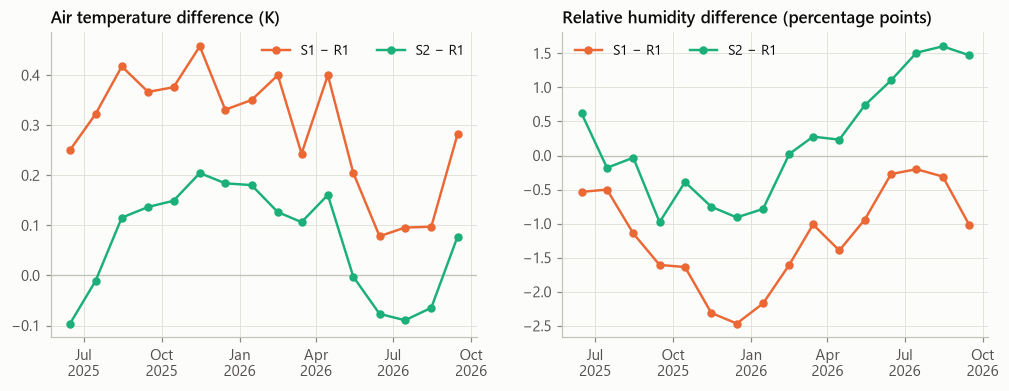

In [11]:
at = by_plot(d12, "air_temp")
dt = at[["S1", "S2"]].sub(at["R1"], axis=0)
rh = by_plot(daily, "rh")
drh = rh[["S1", "S2"]].sub(rh["R1"], axis=0)
dp = by_plot(d12, "dew_point")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for p in ["S1", "S2"]:
    m = dt[p].resample("MS").mean()
    axes[0].plot(m.index + pd.Timedelta(days=14), m, color=PLOT_COLORS[p], marker="o", ms=4.5, label=f"{p} − R1")
    m = drh[p].resample("MS").mean()
    axes[1].plot(m.index + pd.Timedelta(days=14), m, color=PLOT_COLORS[p], marker="o", ms=4.5, label=f"{p} − R1")
axes[0].set_title("Air temperature difference (K)")
axes[1].set_title("Relative humidity difference (percentage points)")
for a, loc in zip(axes, ["upper right", "upper left"]):
    zero_line(a); a.legend(loc=loc, ncols=2)
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); a.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save(fig, "07_air_microclimate")

slot = np.where(dt.index.hour == 0, "00-12 UTC", "12-24 UTC")
print("Air temperature difference by bucket (K):"); display(dt.groupby(slot).agg(["mean", "std"]).round(2))
print("Mean RH difference (pp):", drh.mean().round(2).to_dict())
print("Mean dew-point difference (K):", dp[["S1", "S2"]].sub(dp["R1"], axis=0).mean().round(2).to_dict())

## 8. PV module temperature

Module temperature above ambient (mean of the four module sensors per section minus WS100 air
temperature) against plane-of-array irradiance. There is **no electrical output** (power,
energy, inverter data) in this export.

,S1,S2
K per 100 W/m²,2.00,1.71
intercept K,-0.50,-0.12
r,0.81,0.93
n,894.00,911.00


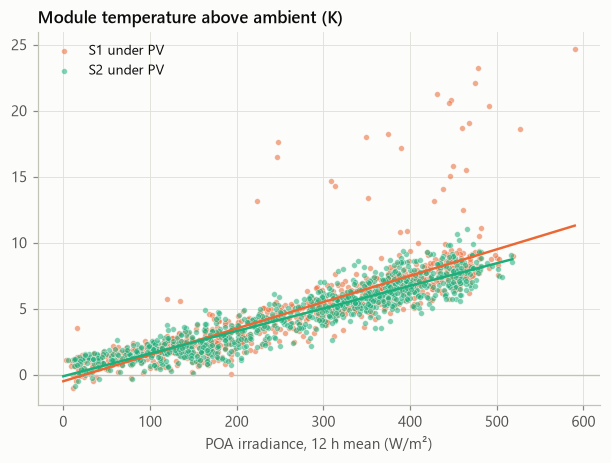

In [12]:
air = d12["WS_air_temp_avg"]
fig, ax = plt.subplots(figsize=(6.6, 4.4))
fits = {}
for p, poa_col in [("S1", "S1_d12_gpoa"), ("S2", "S2_d30_gpoa")]:
    x = pd.concat([d12[poa_col], plot_mean(d12, meta, p, "pv_temp") - air], axis=1, keys=["poa", "excess"]).dropna()
    ax.scatter(x.poa, x.excess, s=14, color=PLOT_COLORS[p], alpha=0.55, edgecolor=SURFACE, linewidth=0.4, label=PLOT_LABELS[p])
    slope, icpt = np.polyfit(x.poa, x.excess, 1)
    fits[p] = (slope * 100, icpt, x.corr().iloc[0, 1], len(x))
    xx = np.array([0, x.poa.max()])
    ax.plot(xx, icpt + slope * xx, color=PLOT_COLORS[p], lw=1.6)
zero_line(ax)
ax.set_xlabel("POA irradiance, 12 h mean (W/m²)")
ax.set_title("Module temperature above ambient (K)")
ax.legend(loc="upper left")
save(fig, "08_pv_thermal")
pd.DataFrame(fits, index=["K per 100 W/m²", "intercept K", "r", "n"]).round(2)

## 9. Trackers

The 12 h mean tilt is negative in the morning bucket (facing east) and positive in the afternoon
bucket (facing west). The heatmap shows each tracker's deviation from the fleet median, which
picks out periods when trackers ran different strategies.

2025: trackers diverge between 2025-05-23 and 2025-06-17
2026: trackers diverge between 2026-05-21 and 2026-06-04
Mean morning-bucket tilt per tracker, May-Jun 2026 (°): {'M01': -16.9, 'M02': -16.9, 'M03': -16.9, 'M04': -16.9, 'M05': -16.9, 'M06': -13.1, 'M07': -13.3, 'M08': -13.5, 'M09': -19.5, 'M10': -19.5}
Buckets where a tracker deviates > 5° from the fleet median, by month:


time,2025-05-01,2025-06-01,2026-05-01,2026-06-01
M01,18,23,11,2
M02,18,25,11,2
M03,18,23,11,2
M04,18,23,11,2
M05,18,23,11,2
M06,18,23,21,7
M07,18,23,21,5
M08,18,23,21,5
M09,18,23,22,5
M10,18,23,21,5


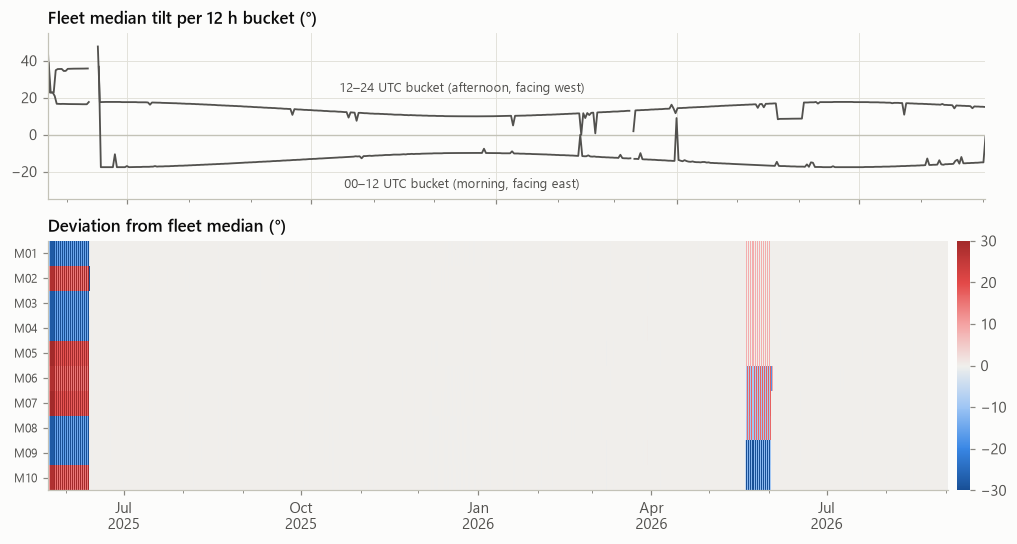

In [13]:
trk = d12.filter(like="TRK_").rename(columns=lambda c: c.split("_")[1])
dev = trk.sub(trk.median(axis=1), axis=0).dropna(how="all")
fleet = trk.median(axis=1)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.5]})
mid = pd.Timestamp("2025-12-15")
for h, name, y in [(0, "00–12 UTC bucket (morning, facing east)", -27), (12, "12–24 UTC bucket (afternoon, facing west)", 25)]:
    s = fleet[fleet.index.hour == h]
    a1.plot(s.index, s, color=INK_SECONDARY, lw=1.2)
    a1.text(mid, y, name, fontsize=8.5, color=INK_SECONDARY, ha="center", va="center")
a1.set_ylim(-35, 55)
zero_line(a1)
a1.set_title("Fleet median tilt per 12 h bucket (°)")
div = LinearSegmentedColormap.from_list("div", style.DIVERGING)
x0, x1 = mdates.date2num(dev.index[0]), mdates.date2num(dev.index[-1])
im = a2.imshow(dev.T.values, aspect="auto", cmap=div, vmin=-30, vmax=30, interpolation="nearest",
               extent=[x0, x1, len(dev.columns) - 0.5, -0.5])
a2.set_yticks(range(len(dev.columns)), dev.columns, fontsize=8)
a2.grid(False)
a2.set_title("Deviation from fleet median (°)")
cb = fig.colorbar(im, ax=a2, fraction=0.03, pad=0.01); cb.outline.set_visible(False)
month_axis(a2)
save(fig, "09_trackers")

off = dev.abs().gt(5)
for year in ("2025", "2026"):
    when = off.loc[year].any(axis=1)
    if when.any():
        print(f"{year}: trackers diverge between {when[when].index.min():%Y-%m-%d} and {when[when].index.max():%Y-%m-%d}")
morning = trk[trk.index.hour == 0]
print("Mean morning-bucket tilt per tracker, May-Jun 2026 (°):", morning.loc["2026-05":"2026-06"].mean().round(1).to_dict())
print("Buckets where a tracker deviates > 5° from the fleet median, by month:")
off.resample("MS").sum().loc[lambda x: x.sum(axis=1) > 0].T

## 10. How the daily variables relate

Spearman rank correlation between daily plot-level variables. Seasonality drives most of the
structure.

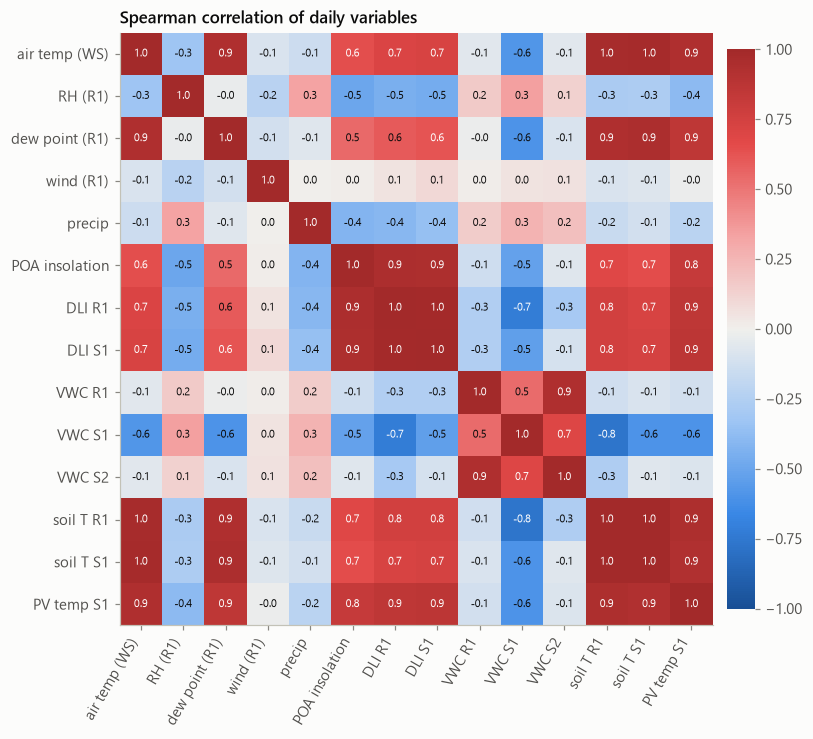

In [14]:
vars_ = pd.DataFrame({
    "air temp (WS)": daily["WS_air_temp_avg"],
    "RH (R1)": daily["R1_d40_rh"],
    "dew point (R1)": daily["R1_d40_dew_point"],
    "wind (R1)": daily["R1_d40_wind_speed"],
    "precip": daily["WS_precip_mm"],
    "POA insolation": daily[["S1_d12_gpoa", "S2_d30_gpoa"]].mean(axis=1) * IRRADIANCE_MEAN_TO_KWH,
    "DLI R1": dli["R1"], "DLI S1": dli["S1"],
    "VWC R1": vwc["R1"], "VWC S1": vwc["S1"], "VWC S2": vwc["S2"],
    "soil T R1": st["R1"], "soil T S1": st["S1"],
    "PV temp S1": plot_mean(daily, meta, "S1", "pv_temp"),
})
corr = vars_.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(corr.values, cmap=LinearSegmentedColormap.from_list("div", style.DIVERGING), vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="#ffffff" if abs(v) > 0.6 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
ax.set_title("Spearman correlation of daily variables")
save(fig, "10_correlations")

## 11. Summary statistics (daily, plot level)

In [15]:
summary_vars = vars_.assign(**{"soil T S2": st["S2"], "DLI S2": dli["S2"]})
summary_vars.describe(percentiles=[0.05, 0.5, 0.95]).T.round(1)

,count,mean,std,min,5%,50%,95%,max
air temp (WS),457.0,18.6,6.7,2.7,8.4,19.3,27.4,28.8
RH (R1),429.0,72.3,9.4,37.6,55.1,72.7,86.7,93.8
dew point (R1),420.0,13.3,6.3,-5.9,3.3,13.8,22.2,24.5
wind (R1),420.0,1.6,0.7,0.0,0.7,1.5,2.7,6.2
precip,462.0,1.3,4.4,0.0,0.0,0.0,10.0,38.6
POA insolation,451.0,6.5,3.2,0.2,1.1,7.2,10.9,12.2
DLI R1,402.0,37.3,19.3,2.0,7.9,36.8,66.2,80.6
DLI S1,436.0,25.6,12.5,1.2,5.4,27.0,45.2,57.6
VWC R1,381.0,23.0,4.8,7.6,10.4,23.9,28.2,35.8
VWC S1,409.0,25.8,5.1,11.5,15.9,26.5,32.7,36.3


## 12. Key findings

### About the data

- **About 15 months of usable data.** The export window starts on 2024-09-24, but sensors only
  come online in late April 2025 (trackers, site weather) and on 2025-06-18 (most field sensors).
  All four R1 soil probes report from 2025-10-08. Soil moisture ends around 2026-09-07; the
  tracker and site-weather feeds end on 2026-09-02.
- **Coarse resolution.** Everything except precipitation is a 12 h mean. Daily totals are exact,
  but the diurnal cycle is not visible.
- **Sensor faults are common.** QC removed or clipped ~500 values. The lasting problems:
  `S2_pv_temp_T1` drifts for weeks; `S1_d20_par` is erratic (excluded from plot means); the PAR
  logger had two outages that reported zeros; soil probes `S1_d17` and `S1_d16` stop in January
  and May 2026.
- **Overlapping sources agree.** Three air-temperature sources correlate at r ≥ 0.997 (WS100
  reads ~0.7 K cooler than the other two). The precipitation counter and integrated intensity
  give 578 vs 548 mm, daily r = 0.99.
- **Weather.** 578 mm of precipitation from mid-June 2025 to late September 2026 (wettest month
  December 2025 with 112 mm; July + August 2026 only 8 mm); ~400 h of rain and ~4 h of snow or
  sleet; prevailing wind from S–SE.

### Agrivoltaic effects (under PV vs open field)

- **Light.** Crops under the panels receive **63–64 % of the open-field daily light integral**
  (monthly 58–73 %), with the higher shares in winter and in September 2026. Individual
  under-panel sensors range from 60 % to 69 % depending on position.
- **Soil temperature.** Under-panel soil is **1–2.5 K cooler in summer** and about the same in
  winter (S2 up to 0.7 K *warmer* in November–December): the panels damp both daytime heating
  and night-time cooling.
- **Soil moisture has no single direction.** S1 is 4–6 points wetter than R1 through winter
  2025/26 and S2 is within ±2 points. In the June 2026 dry-down S1 dried fastest (about 15 %
  vs 21 % in R1). Differences between probes in the same plot (19–31 %) are as large as those
  between plots, so probe position relative to the panel rows matters.
- **Probable irrigation that is not in the data.** From late June to early September 2026 soil
  moisture rises by 7–11 points in every plot, while only ~8 mm of rain fell.
- **Air.** S1 reads 0.3 K warmer than R1 and S2 0.1 K; dew point is identical, and the RH
  differences (−1.2 / +0.2 points) follow from temperature. Offsets this small are within sensor
  tolerance, so a side-by-side calibration check is needed before attributing them to the panels.

### Energy side

- **Module temperature** rises 1.7–2.0 K above ambient per 100 W/m² of 12 h-mean plane-of-array
  irradiance (r = 0.81 for S1, 0.93 for S2). A handful of S1 points sit 13–25 K above ambient and
  should be checked.
- **Plane-of-array insolation** is about 10 kWh/m²/day in June and about 2 in December.
- **Trackers** follow one schedule except twice: during commissioning (23 May–17 Jun 2025, two
  groups about ±30° apart) and on **21 May–4 Jun 2026**, when M01–05, M06–08 and M09–10 held
  different angles. The 2026 split looks like a deliberate strategy trial; worth asking the operator.
- **No PV electrical output** (power, energy, inverter status) is in the export.

### What this means for the intelligent system

1. **Get finer data.** Re-export at 15 min or less, or query the database behind Grafana
   directly. Irrigation detection, heat-stress and frost alerts, and tracker decisions all need
   the diurnal cycle.
2. **Request the missing streams:** PV power and energy, the irrigation log, the crop and
   management calendar (species, sowing, harvest, yield), and tracker setpoints/modes.
3. **Keep QC in the pipeline.** At least five sensors and the PAR logger had multi-week faults in
   15 months; a sensor-health monitor would be useful to the site operator in its own right.
4. **The sample is small** (~400–450 paired days). Start with interpretable, physics-informed
   features (DLI, light transmission, soil water balance, module temperature model) rather
   than data-hungry models.